In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np

# Reproducible random data
np.random.seed(42)

# Total transactions
n = 10000

# Generate transaction data
data = {
    "transaction_id": [f"TXN{i:05d}" for i in range(1, n + 1)],
    "user_id": np.random.randint(1001, 1201, n),
    "amount": np.random.randint(50, 5001, n),
    "merchant_category": np.random.choice(
        ["Shopping", "Food", "Travel", "Bills", "Other"], n
    ),
    "device_type": np.random.choice(
        ["Android", "iOS", "Web"], n
    ),
    "location": np.random.choice(
        ["Delhi", "Mumbai", "Noida", "Bengaluru"], n
    ),
    "is_fraud": np.random.choice(
        [0, 1], n, p=[0.98, 0.02]
    )
}

# Convert dictionary into a DataFrame
df = pd.DataFrame(data)

# Display first five transactions
df.head()

,transaction_id,user_id,amount,merchant_category,device_type,location,is_fraud
0,TXN00001,1103,714,Shopping,Android,Mumbai,0
1,TXN00002,1180,1406,Shopping,Web,Mumbai,0
2,TXN00003,1093,1064,Travel,iOS,Bengaluru,0
3,TXN00004,1015,2182,Bills,Android,Noida,0
4,TXN00005,1107,2718,Bills,iOS,Mumbai,0


In [3]:
# Create a copy of the dataset
df["amount"] = df["amount"].astype(float)

# Select 200 transactions to simulate unusually high amounts
high_amount_indices = df.sample(
    n=200, random_state=42
).index

# Assign unusually high amounts
df.loc[high_amount_indices, "amount"] = np.random.randint(
    15000, 50001, len(high_amount_indices)
)

# Display the largest transactions
df.nlargest(10, "amount")[
    ["transaction_id", "user_id", "amount", "is_fraud"]
]

,transaction_id,user_id,amount,is_fraud
9189,TXN09190,1098,49990.0,0
9317,TXN09318,1067,49838.0,0
2592,TXN02593,1196,49557.0,0
5359,TXN05360,1144,49378.0,0
1068,TXN01069,1090,49370.0,0
9930,TXN09931,1139,49333.0,0
2927,TXN02928,1157,48908.0,0
1963,TXN01964,1064,48824.0,0
3570,TXN03571,1106,48795.0,0
33,TXN00034,1170,48788.0,0


In [4]:
df.loc[high_amount_indices, "is_fraud"] = 1

print("High-amount transactions:", len(high_amount_indices))
print("Total fraud-labeled transactions:", df["is_fraud"].sum())

High-amount transactions: 200
Total fraud-labeled transactions: 420


In [5]:
print("Total transactions:", len(df))
print("\nFraud label distribution:")
print(df["is_fraud"].value_counts())

print("\nTransaction amount statistics:")
print(df["amount"].describe())

Total transactions: 10000

Fraud label distribution:
is_fraud
0    9580
1     420
Name: count, dtype: int64

Transaction amount statistics:
count    10000.000000
mean      3108.730600
std       4647.824222
min         50.000000
25%       1300.000000
50%       2547.000000
75%       3823.250000
max      49990.000000
Name: amount, dtype: float64


In [10]:
# Generate random transaction timestamps

start_date = pd.Timestamp("2026-01-01")
end_date = pd.Timestamp("2026-01-31 23:59:59")

# Calculate total seconds between dates
total_seconds = int((end_date - start_date).total_seconds())

# Generate random seconds
random_seconds = np.random.randint(
    0, total_seconds, size=len(df)
)

# Create transaction timestamps
df["transaction_time"] = (
    start_date + pd.to_timedelta(random_seconds, unit="s")
)

# Extract transaction hour
df["hour"] = df["transaction_time"].dt.hour

# Display first five transactions
df[["transaction_id", "transaction_time", "hour"]].head()

,transaction_id,transaction_time,hour
0,TXN00001,2026-01-17 21:54:27,21
1,TXN00002,2026-01-17 08:01:16,8
2,TXN00003,2026-01-04 00:23:56,0
3,TXN00004,2026-01-07 13:52:08,13
4,TXN00005,2026-01-17 15:14:06,15


In [11]:
start_date = pd.Timestamp("2026-01-01")

In [13]:
np.random.randint(0, total_seconds, size=len(df))

array([1272494,  841737, 2397970, ...,  996598, 1171676, 1932730])

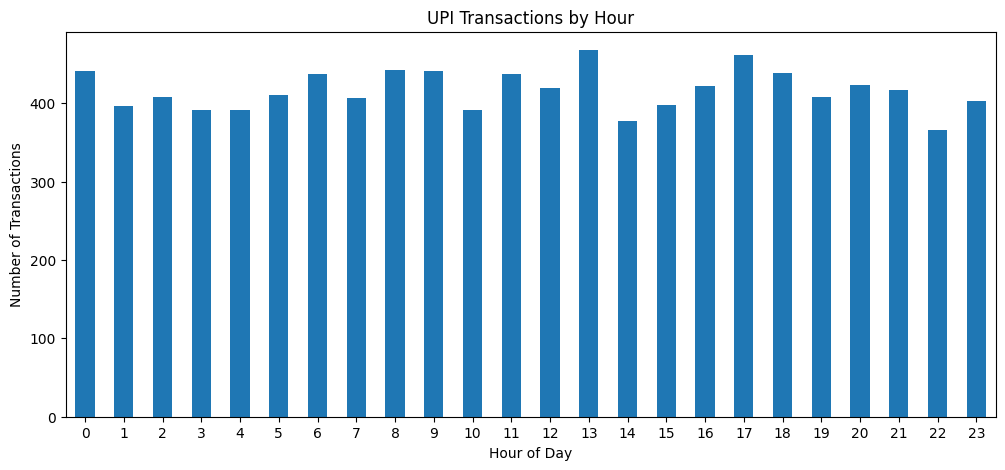

In [14]:
hourly_transactions = df.groupby("hour").size()

hourly_transactions.plot(kind="bar", figsize=(12, 5))

plt.title("UPI Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [15]:
# Compare normal and fraud-labeled transactions

amount_comparison = df.groupby("is_fraud")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

amount_comparison.index = ["Normal", "Fraud-labeled"]

print(amount_comparison)

               count          mean  median    min      max
Normal          9580   2510.353027  2485.5   50.0   5000.0
Fraud-labeled    420  16757.438095  4837.0  121.0  49990.0


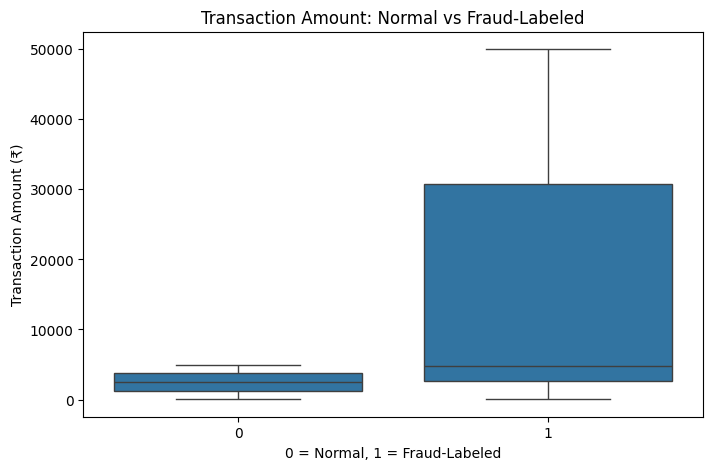

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="is_fraud",
    y="amount"
)

plt.title("Transaction Amount: Normal vs Fraud-Labeled")
plt.xlabel("0 = Normal, 1 = Fraud-Labeled")
plt.ylabel("Transaction Amount (₹)")

plt.show()

In [17]:
# Calculate quartiles
Q1 = df["amount"].quantile(0.25)
Q3 = df["amount"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate upper and lower limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1300.0
Q3: 3823.25
IQR: 2523.25
Lower Bound: -2484.875
Upper Bound: 7608.125


In [18]:
Q1 = df["amount"].quantile(0.25)

In [19]:
IQR = Q3 - Q1

In [20]:
upper_bound = Q3 + 1.5 * IQR

In [21]:
# Flag potential outliers using IQR
df["iqr_flag"] = (
    (df["amount"] < lower_bound) |
    (df["amount"] > upper_bound)
)

# Count flagged transactions
print("Potential outliers:", df["iqr_flag"].sum())

# Display the first 10 flagged transactions
df.loc[
    df["iqr_flag"],
    ["transaction_id", "user_id", "amount", "is_fraud"]
].head(10)

Potential outliers: 200


,transaction_id,user_id,amount,is_fraud
29,TXN00030,1022,30946.0,1
31,TXN00032,1049,33235.0,1
33,TXN00034,1170,48788.0,1
35,TXN00036,1015,38254.0,1
39,TXN00040,1190,47928.0,1
96,TXN00097,1188,30684.0,1
106,TXN00107,1088,18271.0,1
107,TXN00108,1129,48196.0,1
119,TXN00120,1028,22929.0,1
251,TXN00252,1187,23168.0,1


In [22]:
# Compare IQR flags with simulated fraud labels

true_positive = (
    (df["iqr_flag"] == True) &
    (df["is_fraud"] == 1)
).sum()

false_positive = (
    (df["iqr_flag"] == True) &
    (df["is_fraud"] == 0)
).sum()

false_negative = (
    (df["iqr_flag"] == False) &
    (df["is_fraud"] == 1)
).sum()

true_negative = (
    (df["iqr_flag"] == False) &
    (df["is_fraud"] == 0)
).sum()

print("True Positives:", true_positive)
print("False Positives:", false_positive)
print("False Negatives:", false_negative)
print("True Negatives:", true_negative)

True Positives: 200
False Positives: 0
False Negatives: 220
True Negatives: 9580


In [23]:
precision = (
    true_positive / (true_positive + false_positive)
    if (true_positive + false_positive) > 0
    else 0
)

recall = (
    true_positive / (true_positive + false_negative)
    if (true_positive + false_negative) > 0
    else 0
)

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")

Precision: 100.00%
Recall: 47.62%


In [24]:
from sklearn.ensemble import IsolationForest

# Select numerical features
features = df[["amount", "hour"]].copy()

# Train Isolation Forest
model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

model.fit(features)

# Predict anomalies
predictions = model.predict(features)

# Convert predictions into readable labels
df["if_flag"] = predictions == -1

print("Total transactions:", len(df))
print("Isolation Forest anomalies:", df["if_flag"].sum())

df[["transaction_id", "amount", "hour", "if_flag"]].head(10)

Total transactions: 10000
Isolation Forest anomalies: 3140


,transaction_id,amount,hour,if_flag
0,TXN00001,714.0,21,True
1,TXN00002,1406.0,8,False
2,TXN00003,1064.0,0,True
3,TXN00004,2182.0,13,False
4,TXN00005,2718.0,15,False
5,TXN00006,1104.0,15,False
6,TXN00007,1814.0,13,False
7,TXN00008,4508.0,6,False
8,TXN00009,2919.0,19,False
9,TXN00010,1462.0,16,False


In [25]:
features = df[["amount", "hour"]].copy()

In [26]:
IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

IsolationForest(random_state=42)

In [27]:
model.fit(features)

IsolationForest(random_state=42)

In [28]:
predictions = model.predict(features)

In [30]:
# Train a new Isolation Forest model

model_tuned = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

model_tuned.fit(features)

# Predict anomalies
predictions_tuned = model_tuned.predict(features)

df["if_flag_tuned"] = predictions_tuned == -1

print(
    "Isolation Forest anomalies:",
    df["if_flag_tuned"].sum()
)

print(
    "Anomaly percentage:",
    round(df["if_flag_tuned"].mean() * 100, 2),
    "%"
)

Isolation Forest anomalies: 200
Anomaly percentage: 2.0 %


In [31]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_true = df["is_fraud"]
y_pred = df["if_flag_tuned"].astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        zero_division=0
    )
)

Confusion Matrix:
[[9580    0]
 [ 220  200]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      9580
           1       1.00      0.48      0.65       420

    accuracy                           0.98     10000
   macro avg       0.99      0.74      0.82     10000
weighted avg       0.98      0.98      0.97     10000



In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Actual simulated fraud labels
y_true = df["is_fraud"].astype(int)

# IQR predictions
y_iqr = df["iqr_flag"].astype(int)

# Isolation Forest predictions
y_if = df["if_flag_tuned"].astype(int)

# Compare model metrics
comparison = pd.DataFrame({
    "Method": ["IQR", "Isolation Forest"],
    "Precision": [
        precision_score(y_true, y_iqr, zero_division=0),
        precision_score(y_true, y_if, zero_division=0)
    ],
    "Recall": [
        recall_score(y_true, y_iqr, zero_division=0),
        recall_score(y_true, y_if, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_true, y_iqr, zero_division=0),
        f1_score(y_true, y_if, zero_division=0)
    ]
})

print(comparison.round(3))

             Method  Precision  Recall  F1 Score
0               IQR        1.0   0.476     0.645
1  Isolation Forest        1.0   0.476     0.645


In [33]:
# Calculate average transaction amount for each user

df["user_avg_amount"] = df.groupby("user_id")["amount"].transform("mean")

# Calculate how much the transaction differs from user average

df["amount_deviation"] = (
    df["amount"] - df["user_avg_amount"]
)

# Display sample results

df[
    [
        "user_id",
        "amount",
        "user_avg_amount",
        "amount_deviation"
    ]
].head(10)

,user_id,amount,user_avg_amount,amount_deviation
0,1103,714.0,2400.672727,-1686.672727
1,1180,1406.0,4216.804348,-2810.804348
2,1093,1064.0,2769.423729,-1705.423729
3,1015,2182.0,3248.462963,-1066.462963
4,1107,2718.0,3740.232558,-1022.232558
5,1072,1104.0,2969.185185,-1865.185185
6,1189,1814.0,2121.760000,-307.760000
7,1021,4508.0,2058.169811,2449.830189
8,1103,2919.0,2400.672727,518.327273
9,1122,1462.0,2725.058824,-1263.058824


In [34]:
# Count total transactions per user

df["user_transaction_count"] = (
    df.groupby("user_id")["transaction_id"].transform("count")
)

# Display sample results

df[
    [
        "user_id",
        "transaction_id",
        "amount",
        "user_transaction_count"
    ]
].head(10)

,user_id,transaction_id,amount,user_transaction_count
0,1103,TXN00001,714.0,55
1,1180,TXN00002,1406.0,46
2,1093,TXN00003,1064.0,59
3,1015,TXN00004,2182.0,54
4,1107,TXN00005,2718.0,43
5,1072,TXN00006,1104.0,54
6,1189,TXN00007,1814.0,50
7,1021,TXN00008,4508.0,53
8,1103,TXN00009,2919.0,55
9,1122,TXN00010,1462.0,51


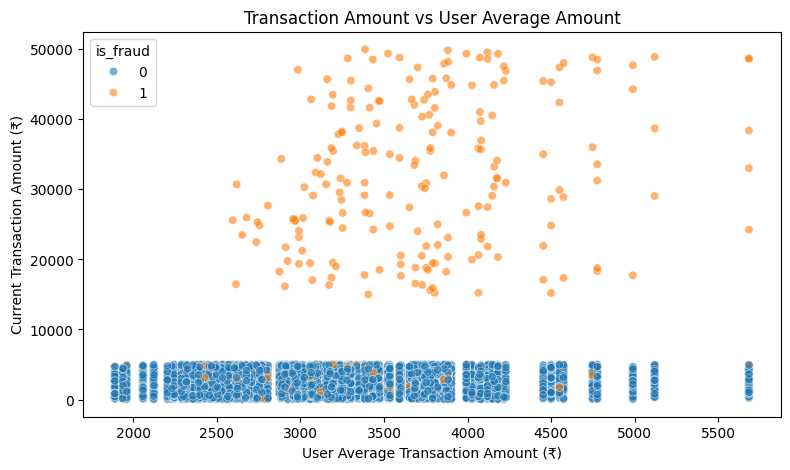

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="user_avg_amount",
    y="amount",
    hue="is_fraud",
    alpha=0.6
)

plt.title("Transaction Amount vs User Average Amount")
plt.xlabel("User Average Transaction Amount (₹)")
plt.ylabel("Current Transaction Amount (₹)")

plt.show()

In [36]:
# Sort transactions by user and time
df = df.sort_values(
    ["user_id", "transaction_time"]
).copy()

# Calculate transactions in the previous hour for each user
df["transactions_last_hour"] = (
    df.groupby("user_id")
    .rolling(
        "1h",
        on="transaction_time",
        closed="left"
    )["transaction_id"]
    .count()
    .reset_index(level=0, drop=True)
    .to_numpy()
)

# Fill missing values and convert to integers
df["transactions_last_hour"] = (
    df["transactions_last_hour"]
    .fillna(0)
    .astype(int)
)

# Display results
print(
    df[
        [
            "user_id",
            "transaction_time",
            "transactions_last_hour"
        ]
    ].head(10)
)

      user_id    transaction_time  transactions_last_hour
950      1001 2026-01-01 01:30:11                       0
1257     1001 2026-01-01 14:23:31                       0
825      1001 2026-01-02 08:51:54                       0
3557     1001 2026-01-03 13:53:13                       0
3627     1001 2026-01-03 15:11:37                       0
137      1001 2026-01-03 19:54:11                       0
7434     1001 2026-01-03 20:41:42                       1
3987     1001 2026-01-04 13:55:57                       0
9444     1001 2026-01-06 14:25:43                       0
1115     1001 2026-01-08 22:57:35                       0


In [37]:
from sklearn.ensemble import IsolationForest

# Select behavioral features
features_v2 = df[
    [
        "amount",
        "hour",
        "amount_deviation",
        "transactions_last_hour"
    ]
].copy()

# Handle any missing or infinite values
features_v2 = features_v2.replace(
    [np.inf, -np.inf], np.nan
)

features_v2 = features_v2.fillna(0)

# Train the updated model
model_v2 = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

model_v2.fit(features_v2)

# Predict anomalies
df["if_flag_v2"] = (
    model_v2.predict(features_v2) == -1
)

print(
    "Total transactions:",
    len(df)
)

print(
    "Detected anomalies:",
    df["if_flag_v2"].sum()
)

print(
    "Anomaly percentage:",
    round(df["if_flag_v2"].mean() * 100, 2),
    "%"
)

Total transactions: 10000
Detected anomalies: 200
Anomaly percentage: 2.0 %


In [38]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Actual simulated fraud labels
y_true = df["is_fraud"].astype(int)

# Updated model predictions
y_pred_v2 = df["if_flag_v2"].astype(int)

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_v2))

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred_v2,
        zero_division=0
    )
)

Confusion Matrix:
[[9566   14]
 [ 234  186]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      9580
           1       0.93      0.44      0.60       420

    accuracy                           0.98     10000
   macro avg       0.95      0.72      0.79     10000
weighted avg       0.97      0.98      0.97     10000



In [39]:
!pip install -q streamlit plotly

In [40]:
import pandas as pd
import plotly.express as px
from IPython.display import display, HTML

# 1. Dashboard title
display(HTML("""
<h1 style='text-align:center;'>UPI Fraud Detection Dashboard</h1>
<p style='text-align:center;'>
Transaction Analysis & Anomaly Detection
</p>
"""))

# 2. Calculate important metrics
total_transactions = len(df)
suspicious_transactions = int(df["if_flag_v2"].sum())
normal_transactions = total_transactions - suspicious_transactions
suspicious_rate = (suspicious_transactions / total_transactions) * 100

# 3. Display summary
summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Suspicious Transactions",
        "Normal Transactions",
        "Suspicious Transaction Rate"
    ],
    "Value": [
        total_transactions,
        suspicious_transactions,
        normal_transactions,
        f"{suspicious_rate:.2f}%"
    ]
})

display(summary)

# 4. Transaction amount distribution
fig1 = px.histogram(
    df,
    x="amount",
    color="if_flag_v2",
    nbins=50,
    title="Transaction Amount Distribution",
    labels={
        "amount": "Transaction Amount (₹)",
        "if_flag_v2": "Suspicious Transaction"
    }
)

fig1.show()

# 5. Normal vs suspicious transaction count
comparison = pd.DataFrame({
    "Transaction Type": ["Normal", "Suspicious"],
    "Count": [normal_transactions, suspicious_transactions]
})

fig2 = px.bar(
    comparison,
    x="Transaction Type",
    y="Count",
    color="Transaction Type",
    title="Normal vs Suspicious Transactions",
    text="Count"
)

fig2.show()

# 6. Suspicious transactions table
suspicious_df = df[df["if_flag_v2"]].copy()

columns_to_show = [
    "transaction_id",
    "user_id",
    "amount",
    "merchant_category",
    "device_type",
    "location",
    "transaction_time"
]

display(
    suspicious_df[columns_to_show]
    .sort_values("amount", ascending=False)
    .head(20)
)

print("Dashboard generated successfully!")

,Metric,Value
0,Total Transactions,10000
1,Suspicious Transactions,200
2,Normal Transactions,9800
3,Suspicious Transaction Rate,2.00%


,transaction_id,user_id,amount,merchant_category,device_type,location,transaction_time
9189,TXN09190,1098,49990.0,Food,Android,Noida,2026-01-22 05:03:49
9317,TXN09318,1067,49838.0,Food,Android,Noida,2026-01-29 12:12:03
2592,TXN02593,1196,49557.0,Other,iOS,Delhi,2026-01-17 03:20:03
5359,TXN05360,1144,49378.0,Bills,Web,Delhi,2026-01-18 11:44:50
1068,TXN01069,1090,49370.0,Other,iOS,Delhi,2026-01-28 16:46:18
9930,TXN09931,1139,49333.0,Food,Web,Noida,2026-01-10 12:21:27
2927,TXN02928,1157,48908.0,Food,Web,Mumbai,2026-01-10 03:12:03
1963,TXN01964,1064,48824.0,Food,iOS,Bengaluru,2026-01-03 15:59:41
3570,TXN03571,1106,48795.0,Shopping,Web,Bengaluru,2026-01-16 19:59:21
33,TXN00034,1170,48788.0,Travel,Android,Mumbai,2026-01-20 11:01:53


Dashboard generated successfully!


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd
import numpy as np

# Step 1: Select features
features = [
    "amount",
    "hour",
    "amount_deviation",
    "transactions_last_hour"
]

X = df[features].copy()
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

# Actual simulated labels
y = df["is_fraud"].astype(int)

# Step 2: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 3: Display dataset sizes
print("Training transactions:", len(X_train))
print("Testing transactions:", len(X_test))

print("\nFraud labels in training data:", int(y_train.sum()))
print("Fraud labels in testing data:", int(y_test.sum()))

Training transactions: 8000
Testing transactions: 2000

Fraud labels in training data: 336
Fraud labels in testing data: 84


In [44]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

# Step 1: Create the model
model_test = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

# Step 2: Train only on training data
model_test.fit(X_train)

# Step 3: Predict anomalies in unseen testing data
predictions = model_test.predict(X_test)

# Isolation Forest: -1 means anomaly, 1 means normal
y_pred = (predictions == -1).astype(int)

# Step 4: Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Confusion Matrix:
[[1913    3]
 [  43   41]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1916
           1       0.93      0.49      0.64        84

    accuracy                           0.98      2000
   macro avg       0.95      0.74      0.81      2000
weighted avg       0.98      0.98      0.97      2000



In [45]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

results = []

contamination_values = [0.02, 0.03, 0.05, 0.08]

for contamination in contamination_values:

    model = IsolationForest(
        n_estimators=100,
        contamination=contamination,
        random_state=42
    )

    model.fit(X_train)

    predictions = model.predict(X_test)

    y_pred_temp = (predictions == -1).astype(int)

    results.append({
        "Contamination": contamination,
        "Precision": precision_score(y_test, y_pred_temp, zero_division=0),
        "Recall": recall_score(y_test, y_pred_temp, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred_temp, zero_division=0),
        "Detected Anomalies": int(y_pred_temp.sum())
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Contamination,Precision,Recall,F1 Score,Detected Anomalies
0,0.02,0.932,0.488,0.641,44
1,0.03,0.690,0.583,0.632,71
2,0.05,0.510,0.619,0.559,102
3,0.08,0.329,0.643,0.435,164


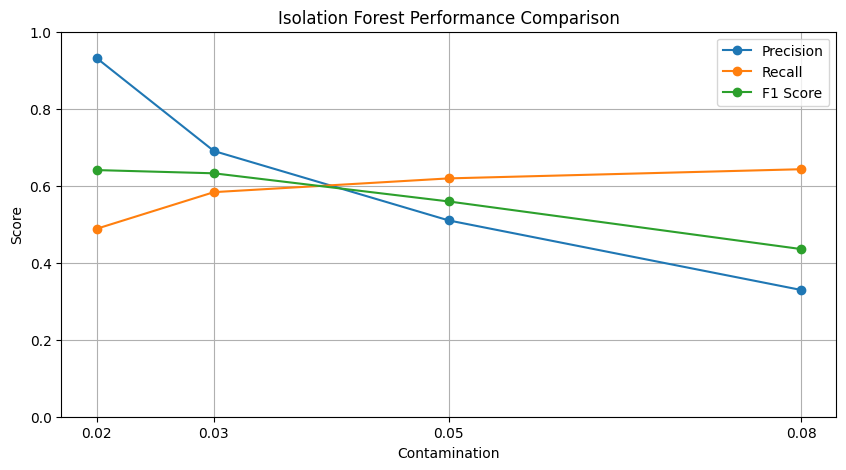

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Contamination"],
    results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["Contamination"],
    results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["Contamination"],
    results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.title("Isolation Forest Performance Comparison")
plt.xlabel("Contamination")
plt.ylabel("Score")
plt.xticks(results_df["Contamination"])
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()